# Data Preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
water = pd.read_csv('/Users/yudhapratama/Documents/Science/Publikasi/clean-water-access/data/06b06ead-5b46-4c1c-8d80-7b410268b3aa_Data.csv',encoding='latin1')
water

,Provinces Name,Provinces Code,Time,Time Code,Household Access to Safe Water (in % of total household) [HOU.H2O.ACSN.ZS],Total Expenditure (in IDR) [EC.XPD.TOTL.CR],Morbidity Rate (in %) [SH.MORB.ZS],"Human Development Index, revised method [IDX.HDI.REV]",Total Population (in number of people) [SP.POP.TOTL],Total Own Source Revenue/PAD (in IDR) [REV.OSRV.CR],Total Area (in Km²) [LND.TOTL.K2]
0,"Badung, Kab.",ID.BA.BD,1976.0,YR1976,..,..,..,..,..,..,..
1,"Badung, Kab.",ID.BA.BD,1977.0,YR1977,..,..,..,..,..,..,..
2,"Badung, Kab.",ID.BA.BD,1978.0,YR1978,..,..,..,..,..,..,..
3,"Badung, Kab.",ID.BA.BD,1979.0,YR1979,..,..,..,..,..,..,..
4,"Badung, Kab.",ID.BA.BD,1980.0,YR1980,..,..,..,..,..,..,..
...,...,...,...,...,...,...,...,...,...,...,...
23130,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23131,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23132,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
23133,Data from database: Indonesia Database for Pol...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
water.dropna(inplace=True)
water

,Provinces Name,Provinces Code,Time,Time Code,Household Access to Safe Water (in % of total household) [HOU.H2O.ACSN.ZS],Total Expenditure (in IDR) [EC.XPD.TOTL.CR],Morbidity Rate (in %) [SH.MORB.ZS],"Human Development Index, revised method [IDX.HDI.REV]",Total Population (in number of people) [SP.POP.TOTL],Total Own Source Revenue/PAD (in IDR) [REV.OSRV.CR],Total Area (in Km²) [LND.TOTL.K2]
0,"Badung, Kab.",ID.BA.BD,1976.0,YR1976,..,..,..,..,..,..,..
1,"Badung, Kab.",ID.BA.BD,1977.0,YR1977,..,..,..,..,..,..,..
2,"Badung, Kab.",ID.BA.BD,1978.0,YR1978,..,..,..,..,..,..,..
3,"Badung, Kab.",ID.BA.BD,1979.0,YR1979,..,..,..,..,..,..,..
4,"Badung, Kab.",ID.BA.BD,1980.0,YR1980,..,..,..,..,..,..,..
...,...,...,...,...,...,...,...,...,...,...,...
23125,"Toba Samosir, Kab.",ID.SU.TR,2016.0,YR2016,60.8014526367188,1010631910908,21.137134552002,73.61,180694,54391304393.22,..
23126,"Toba Samosir, Kab.",ID.SU.TR,2017.0,YR2017,63.1019592285156,1100661584284.6,24.2077350616455,73.87,181790,54840823646.03,..
23127,"Toba Samosir, Kab.",ID.SU.TR,2018.0,YR2018,71.376953125,1055027173780.2,21.7724475860596,74.48,182673,52298960803.4,..
23128,"Toba Samosir, Kab.",ID.SU.TR,2019.0,YR2019,59.2871131896973,1061087958908.41,20.8693084716797,74.92,183712,68046526605.06,..


In [4]:
kolom = {
    'Provinces Name' : 'kota',
    'Provinces Code' : 'id',
    'Time' : 'yr',
    'Household Access to Safe Water (in % of total household) [HOU.H2O.ACSN.ZS]':'water',
    'Total Expenditure (in IDR) [EC.XPD.TOTL.CR]' : 'expend',
    'Morbidity Rate (in %) [SH.MORB.ZS]' : 'morbid',
    'Total Area (in Km²) [LND.TOTL.K2]' : 'area',
    'Human Development Index, revised method [IDX.HDI.REV]' : 'hdi',
    'Total Population (in number of people) [SP.POP.TOTL]':'pop',
    'Total Own Source Revenue/PAD (in IDR) [REV.OSRV.CR]':'pad',
    'Number of people employed [SL.EMP.TOTL]':'employ'  
}
water.rename(columns=kolom,inplace=True)

In [5]:
water.replace({'..': np.nan},inplace=True)
water.isna().sum()

kota             0
id               0
yr               0
Time Code        0
water        12537
expend       14452
morbid       12540
hdi          18057
pop           8647
pad          12094
area         19172
dtype: int64

In [6]:
water['area'] = water.groupby('id')['area'].transform(lambda x: x.ffill().bfill())
water.head(40)

,kota,id,yr,Time Code,water,expend,morbid,hdi,pop,pad,area
0,"Badung, Kab.",ID.BA.BD,1976.0,YR1976,NaN,NaN,NaN,NaN,NaN,NaN,419
1,"Badung, Kab.",ID.BA.BD,1977.0,YR1977,NaN,NaN,NaN,NaN,NaN,NaN,419
2,"Badung, Kab.",ID.BA.BD,1978.0,YR1978,NaN,NaN,NaN,NaN,NaN,NaN,419
3,"Badung, Kab.",ID.BA.BD,1979.0,YR1979,NaN,NaN,NaN,NaN,NaN,NaN,419
4,"Badung, Kab.",ID.BA.BD,1980.0,YR1980,NaN,NaN,NaN,NaN,NaN,NaN,419
5,"Badung, Kab.",ID.BA.BD,1981.0,YR1981,NaN,NaN,NaN,NaN,NaN,NaN,419
6,"Badung, Kab.",ID.BA.BD,1982.0,YR1982,NaN,NaN,NaN,NaN,NaN,NaN,419
7,"Badung, Kab.",ID.BA.BD,1983.0,YR1983,NaN,NaN,NaN,NaN,547595,NaN,419
8,"Badung, Kab.",ID.BA.BD,1984.0,YR1984,NaN,NaN,NaN,NaN,562809,NaN,419
9,"Badung, Kab.",ID.BA.BD,1985.0,YR1985,NaN,NaN,NaN,NaN,578445,NaN,419


## Imputasi

1. imp_knn = KNNImputer(n_neighbors=5, weights="uniform") Here, you are configuring the "rules" for how you want to guess the missing data:

n_neighbors=5: When the computer finds a missing value, it will look at the 5 most similar rows (neighbors) in your dataset to figure out what the missing value should be.
weights="uniform": This means all 5 of those neighboring rows get an equal say (vote) in guessing the missing value. The missing value is replaced by the simple average of those 5 neighbors.

2. water[['expend','pop','pad']] = imp_knn.fit_transform(...) This line is where the actual math happens, specifically on the expend, pop, and pad columns:

.fit(): The imputer studies those three columns to understand the relationships between the data points.
.transform(): It finds any missing values (NaNs) in those three columns and replaces them with the averages of their 5 nearest neighbors.
Finally, it takes this new, cleaned-up data and overwrites the original expend, pop, and pad columns in your water DataFrame so they no longer contain any missing data.

In [7]:
from sklearn.impute import KNNImputer

In [8]:
imp_knn = KNNImputer(n_neighbors=5, weights="uniform")
water[['expend','pop','pad']] = imp_knn.fit_transform(water[['expend','pop','pad']])

In [10]:
water.describe()

,yr,expend,pop,pad
count,23130.000000,2.313000e+04,2.313000e+04,2.313000e+04
mean,1998.000000,9.334324e+11,5.453190e+05,1.077149e+11
std,12.987454,6.606801e+11,4.627944e+05,2.172693e+11
min,1976.000000,0.000000e+00,1.260700e+04,0.000000e+00
25%,1987.000000,5.592358e+11,2.516910e+05,2.625351e+10
50%,1998.000000,9.363017e+11,5.459447e+05,9.356052e+10
75%,2009.000000,9.363017e+11,5.459447e+05,9.356052e+10
max,2020.000000,9.162656e+12,6.398000e+06,5.381920e+12


In [12]:
water = water[water['area'].notna()]
water.isna().sum()

kota             0
id               0
yr               0
Time Code        0
water        11260
expend           0
morbid       11267
hdi          16695
pop              0
pad              0
area             0
dtype: int64

### Feature Engineering

In [13]:
water['yr'] = pd.to_datetime(water['yr'])
water['yr'] = water['yr'].dt.year
water['water'] = water.water.astype('float')
water['area'] = water.area.astype('float')
water['morbid'] = water.morbid.astype('float')

water[['water','area','morbid','pad','expend']] = water[['water','area','morbid','pad','expend']].round(2)

print(water.dtypes)

kota             str
id               str
yr             int32
Time Code        str
water        float64
expend       float64
morbid       float64
hdi              str
pop          float64
pad          float64
area         float64
dtype: object


In [14]:
water = water[~water["kota"].str.contains('Prop.')]
water['Time Code'] = water['Time Code'].str.replace('YR','')
water.rename(columns={'Time Code':'year'},inplace=True)

water[['daerah','tingkat']] = water['kota'].str.split(',', expand=True)
water['tingkat'] = water['tingkat'].str.strip()
water['daerah'] = water['daerah'].str.strip()
water

,kota,id,yr,year,water,expend,morbid,hdi,pop,pad,area,daerah,tingkat
0,"Badung, Kab.",ID.BA.BD,1970,1976,NaN,9.363017e+11,NaN,NaN,545944.66326,9.356052e+10,419.00,Badung,Kab.
1,"Badung, Kab.",ID.BA.BD,1970,1977,NaN,9.363017e+11,NaN,NaN,545944.66326,9.356052e+10,419.00,Badung,Kab.
2,"Badung, Kab.",ID.BA.BD,1970,1978,NaN,9.363017e+11,NaN,NaN,545944.66326,9.356052e+10,419.00,Badung,Kab.
3,"Badung, Kab.",ID.BA.BD,1970,1979,NaN,9.363017e+11,NaN,NaN,545944.66326,9.356052e+10,419.00,Badung,Kab.
4,"Badung, Kab.",ID.BA.BD,1970,1980,NaN,9.363017e+11,NaN,NaN,545944.66326,9.356052e+10,419.00,Badung,Kab.
...,...,...,...,...,...,...,...,...,...,...,...,...,...
23125,"Toba Samosir, Kab.",ID.SU.TR,1970,2016,60.80,1.010632e+12,21.14,73.61,180694.00000,5.439130e+10,2328.89,Toba Samosir,Kab.
23126,"Toba Samosir, Kab.",ID.SU.TR,1970,2017,63.10,1.100662e+12,24.21,73.87,181790.00000,5.484082e+10,2328.89,Toba Samosir,Kab.
23127,"Toba Samosir, Kab.",ID.SU.TR,1970,2018,71.38,1.055027e+12,21.77,74.48,182673.00000,5.229896e+10,2328.89,Toba Samosir,Kab.
23128,"Toba Samosir, Kab.",ID.SU.TR,1970,2019,59.29,1.061088e+12,20.87,74.92,183712.00000,6.804653e+10,2328.89,Toba Samosir,Kab.


In [16]:
water[water['kota'].str.contains("Bandung")]

,kota,id,yr,year,water,expend,morbid,hdi,pop,pad,area,daerah,tingkat
2475,"Bandung Barat, Kab.",ID.JR.BB,1970,1976,NaN,9.363017e+11,NaN,NaN,5.459447e+05,9.356052e+10,1305.77,Bandung Barat,Kab.
2476,"Bandung Barat, Kab.",ID.JR.BB,1970,1977,NaN,9.363017e+11,NaN,NaN,5.459447e+05,9.356052e+10,1305.77,Bandung Barat,Kab.
2477,"Bandung Barat, Kab.",ID.JR.BB,1970,1978,NaN,9.363017e+11,NaN,NaN,5.459447e+05,9.356052e+10,1305.77,Bandung Barat,Kab.
2478,"Bandung Barat, Kab.",ID.JR.BB,1970,1979,NaN,9.363017e+11,NaN,NaN,5.459447e+05,9.356052e+10,1305.77,Bandung Barat,Kab.
2479,"Bandung Barat, Kab.",ID.JR.BB,1970,1980,NaN,9.363017e+11,NaN,NaN,5.459447e+05,9.356052e+10,1305.77,Bandung Barat,Kab.
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2605,"Bandung, Kota",ID.JR.BN,1970,2016,87.92,5.830414e+12,26.99,80.13,2.490622e+06,2.152756e+12,167.67,Bandung,Kota
2606,"Bandung, Kota",ID.JR.BN,1970,2017,92.49,5.541718e+12,33.34,80.31,2.497938e+06,2.578457e+12,167.67,Bandung,Kota
2607,"Bandung, Kota",ID.JR.BN,1970,2018,93.30,6.114449e+12,33.86,81.06,2.503708e+06,2.571592e+12,167.67,Bandung,Kota
2608,"Bandung, Kota",ID.JR.BN,1970,2019,94.89,6.312147e+12,31.37,81.62,2.507888e+06,2.548259e+12,167.67,Bandung,Kota


In [17]:
water.drop(columns=['hdi','kota','yr'], inplace=True)

## Exploratory Data Analysis

Filter only 25 years of Data

In [18]:
water['year'] = water['year'].astype(int)
df = water[water['year'] > 1995]
df

,id,year,water,expend,morbid,pop,pad,area,daerah,tingkat
20,ID.BA.BD,1996,42.52,1.977963e+11,28.46,315600.0,8.081535e+10,419.00,Badung,Kab.
21,ID.BA.BD,1997,38.60,1.977963e+11,28.05,322100.0,9.578920e+10,419.00,Badung,Kab.
22,ID.BA.BD,1998,40.72,1.977963e+11,23.42,328700.0,2.174454e+11,419.00,Badung,Kab.
23,ID.BA.BD,1999,36.70,1.977963e+11,32.92,335300.0,2.539003e+11,419.00,Badung,Kab.
24,ID.BA.BD,2000,48.57,1.977963e+11,26.37,339953.0,2.190000e+11,419.00,Badung,Kab.
...,...,...,...,...,...,...,...,...,...,...
23125,ID.SU.TR,2016,60.80,1.010632e+12,21.14,180694.0,5.439130e+10,2328.89,Toba Samosir,Kab.
23126,ID.SU.TR,2017,63.10,1.100662e+12,24.21,181790.0,5.484082e+10,2328.89,Toba Samosir,Kab.
23127,ID.SU.TR,2018,71.38,1.055027e+12,21.77,182673.0,5.229896e+10,2328.89,Toba Samosir,Kab.
23128,ID.SU.TR,2019,59.29,1.061088e+12,20.87,183712.0,6.804653e+10,2328.89,Toba Samosir,Kab.


In [19]:
df.isna().sum()

id            0
year          0
water      1720
expend        0
morbid     1727
pop           0
pad           0
area          0
daerah        0
tingkat      25
dtype: int64

Check zero values

In [20]:
print(df[(df['expend']==0)])
df[df['daerah']=='Sekadau']

            id  year  water  expend  morbid       pop           pad    area  \
7506  ID.KB.SE  2012  21.18     0.0   30.31  187310.0  1.836491e+10  5444.2   

       daerah tingkat  
7506  Sekadau    Kab.  


,id,year,water,expend,morbid,pop,pad,area,daerah,tingkat
7490,ID.KB.SE,1996,NaN,9.363017e+11,NaN,545944.66326,9.356052e+10,5474.2,Sekadau,Kab.
7491,ID.KB.SE,1997,NaN,9.363017e+11,NaN,545944.66326,9.356052e+10,5474.2,Sekadau,Kab.
7492,ID.KB.SE,1998,NaN,9.363017e+11,NaN,545944.66326,9.356052e+10,5474.2,Sekadau,Kab.
7493,ID.KB.SE,1999,NaN,9.363017e+11,NaN,545944.66326,9.356052e+10,5474.2,Sekadau,Kab.
7494,ID.KB.SE,2000,NaN,9.363017e+11,NaN,545944.66326,9.356052e+10,5474.2,Sekadau,Kab.
7495,ID.KB.SE,2001,NaN,9.363017e+11,NaN,545944.66326,9.356052e+10,5474.2,Sekadau,Kab.
7496,ID.KB.SE,2002,NaN,9.363017e+11,NaN,545944.66326,9.356052e+10,5474.2,Sekadau,Kab.
7497,ID.KB.SE,2003,NaN,9.363017e+11,NaN,545944.66326,9.356052e+10,5474.2,Sekadau,Kab.
7498,ID.KB.SE,2004,NaN,9.101313e+11,NaN,169304.00000,4.112030e+10,5474.2,Sekadau,Kab.
7499,ID.KB.SE,2005,9.25,9.683978e+10,29.64,172042.00000,7.657753e+08,5474.2,Sekadau,Kab.


In [21]:
df[(df['pad']==0)]
df[df['daerah']=='Semarang']

,id,year,water,expend,morbid,pop,pad,area,daerah,tingkat
4835,ID.JT.SM,1996,47.56,1.977963e+11,25.69,812400.0,8.152724e+09,982.00,Semarang,Kab.
4836,ID.JT.SM,1997,44.89,2.506097e+11,22.14,815200.0,9.635262e+09,982.00,Semarang,Kab.
4837,ID.JT.SM,1998,51.85,1.977963e+11,25.27,817600.0,1.121762e+10,982.00,Semarang,Kab.
4838,ID.JT.SM,1999,51.66,1.977963e+11,32.12,819500.0,1.206929e+10,982.00,Semarang,Kab.
4839,ID.JT.SM,2000,52.93,1.977963e+11,34.08,833214.0,4.874141e+10,982.00,Semarang,Kab.
4840,ID.JT.SM,2001,58.92,2.300897e+11,23.62,836334.0,1.892318e+10,950.21,Semarang,Kab.
4841,ID.JT.SM,2002,57.92,2.830786e+11,24.79,839512.0,3.005862e+10,950.21,Semarang,Kab.
4842,ID.JT.SM,2003,50.35,3.577696e+11,21.77,842647.0,4.026971e+10,950.21,Semarang,Kab.
4843,ID.JT.SM,2004,57.54,3.635699e+11,25.33,888430.0,4.463464e+10,950.21,Semarang,Kab.
4844,ID.JT.SM,2005,62.77,3.736693e+11,17.84,894481.0,5.651182e+10,950.21,Semarang,Kab.


Ada 6 Observasi yang pad dan expend nya 0. Ini tidak masuk akal. Maka saya coba untuk melakukan Itrative Imputer. Saya mengahapus dulu nilai 0 dan kemudian diganti dengan nan yang akan dimasukan imputer berdasarkan regresi

### KKN Imputer (2)

In [22]:
df[['expend','pad']] = df[['expend','pad']].replace({0: np.nan})
imp_knn = KNNImputer(n_neighbors=5, weights="uniform")
df[['expend','pop','pad']] = imp_knn.fit_transform(df[['expend','pop','pad']])
df.describe()

,year,water,expend,morbid,pop,pad,area
count,11925.000000,10205.000000,1.192500e+04,10198.000000,1.192500e+04,1.192500e+04,11925.000000
mean,2008.000000,53.471524,8.315921e+11,28.358483,5.294878e+05,9.824804e+10,4714.238787
std,7.211405,22.310100,7.399928e+11,8.646367,5.528503e+05,2.393469e+11,7933.970360
min,1996.000000,0.000000,1.650104e+08,2.860000,1.260700e+04,4.026000e+06,6.000000
25%,2002.000000,36.840000,2.745891e+11,22.540000,1.764660e+05,1.284884e+10,864.930000
50%,2008.000000,53.490000,7.170876e+11,27.850000,3.663150e+05,4.189033e+10,2040.110000
75%,2014.000000,70.400000,9.982711e+11,33.720000,6.235360e+05,9.356052e+10,5101.760000
max,2020.000000,100.000000,9.162656e+12,77.120000,6.398000e+06,5.381920e+12,119749.000000


### Check Missing Values

In [23]:
df[df.isna().any(axis=1)]

,id,year,water,expend,morbid,pop,pad,area,daerah,tingkat
425,ID.BT.CL,1996,NaN,9.363017e+11,NaN,545944.663260,9.356052e+10,176.00,Cilegon,Kota
426,ID.BT.CL,1997,NaN,9.363017e+11,NaN,545944.663260,9.356052e+10,176.00,Cilegon,Kota
427,ID.BT.CL,1998,NaN,9.363017e+11,NaN,545944.663260,9.356052e+10,176.00,Cilegon,Kota
428,ID.BT.CL,1999,NaN,9.363017e+11,NaN,545944.663260,9.356052e+10,176.00,Cilegon,Kota
429,ID.BT.CL,2000,NaN,3.030653e+11,NaN,241412.200000,1.693364e+10,176.00,Cilegon,Kota
...,...,...,...,...,...,...,...,...,...,...
22753,ID.SU.SD,2004,NaN,1.493141e+12,NaN,574312.003407,1.075152e+11,2156.26,Serdang Bedagai,Kab.
23105,ID.SU.TR,1996,NaN,9.363017e+11,NaN,545944.663260,9.356052e+10,3440.85,Toba Samosir,Kab.
23106,ID.SU.TR,1997,NaN,9.363017e+11,NaN,545944.663260,9.356052e+10,3440.85,Toba Samosir,Kab.
23107,ID.SU.TR,1998,NaN,9.363017e+11,NaN,545944.663260,9.356052e+10,3440.85,Toba Samosir,Kab.


In [24]:
df.dropna(subset=['water'], inplace=True)
df.isna().sum()

id          0
year        0
water       0
expend      0
morbid     25
pop         0
pad         0
area        0
daerah      0
tingkat    24
dtype: int64

In [25]:
df.dropna(subset=['morbid'], inplace=True)
df.isna().sum()

id          0
year        0
water       0
expend      0
morbid      0
pop         0
pad         0
area        0
daerah      0
tingkat    24
dtype: int64

In [26]:
df[df.isna().any(axis=1)]

,id,year,water,expend,morbid,pop,pad,area,daerah,tingkat
18876,ID.SG.KC,1997,59.27,2.137248e+11,11.83,525720.6,2.953715e+09,188.00,Kendari City,NaN
18877,ID.SG.KC,1998,54.52,4.052570e+11,20.08,483250.2,3.432473e+09,188.00,Kendari City,NaN
18878,ID.SG.KC,1999,62.76,3.987241e+11,15.33,497529.4,4.038143e+09,188.00,Kendari City,NaN
18879,ID.SG.KC,2000,79.96,1.977963e+11,26.91,203239.0,4.046346e+09,188.00,Kendari City,NaN
18880,ID.SG.KC,2001,69.47,9.260861e+10,29.06,208349.0,7.096788e+09,296.00,Kendari City,NaN
18881,ID.SG.KC,2002,73.91,1.405628e+11,28.72,216135.0,1.538560e+10,295.89,Kendari City,NaN
18882,ID.SG.KC,2003,69.49,1.936028e+11,19.14,222466.0,1.389328e+10,295.89,Kendari City,NaN
18883,ID.SG.KC,2004,67.89,1.979635e+11,24.44,222198.0,1.411254e+10,295.89,Kendari City,NaN
18884,ID.SG.KC,2005,70.86,2.075840e+11,29.48,227027.0,1.597818e+10,300.89,Kendari City,NaN
18885,ID.SG.KC,2006,75.20,2.958307e+11,27.81,242917.0,2.014639e+10,300.89,Kendari City,NaN


## Artibatry Input a Value on a Column

In [27]:
df.loc[df['daerah'] == 'Kendari City', 'tingkat'] = 'Kota'
df[df.isna().any(axis=1)]

,id,year,water,expend,morbid,pop,pad,area,daerah,tingkat


## Check Duplicates

In [28]:
duplicates = df[df.duplicated(subset=['daerah', 'year'], keep=False)]
# Sort them so the duplicates are right next to each other
duplicates.sort_values(by=['daerah', 'year']).head(20)

,id,year,water,expend,morbid,pop,pad,area,daerah,tingkat
2540,ID.JR.BD,1996,27.18,1.977963e+11,22.85,3.422000e+06,2.655460e+10,1422.00,Bandung,Kab.
2585,ID.JR.BN,1996,64.23,1.977963e+11,21.60,2.429000e+06,6.112594e+10,81.00,Bandung,Kota
2541,ID.JR.BD,1997,27.02,1.977963e+11,21.24,3.452300e+06,3.332423e+10,1422.00,Bandung,Kab.
2586,ID.JR.BN,1997,61.33,1.977963e+11,18.73,2.490100e+06,6.519390e+10,81.00,Bandung,Kota
2542,ID.JR.BD,1998,32.80,1.977963e+11,19.24,3.480900e+06,3.977242e+10,1422.00,Bandung,Kab.
2587,ID.JR.BN,1998,64.11,1.977963e+11,26.15,2.551300e+06,7.266765e+10,81.00,Bandung,Kota
2543,ID.JR.BD,1999,26.82,1.977963e+11,16.78,3.507700e+06,4.817412e+10,1422.00,Bandung,Kab.
2588,ID.JR.BN,1999,65.63,3.654460e+11,25.10,2.613000e+06,9.428384e+10,81.00,Bandung,Kota
2544,ID.JR.BD,2000,31.32,4.974545e+11,20.03,4.158083e+06,5.036725e+10,1422.00,Bandung,Kab.
2589,ID.JR.BN,2000,53.83,1.977963e+11,18.93,2.136260e+06,7.544935e+10,81.00,Bandung,Kota


In [29]:
df['daerah_lengkap'] = df['tingkat'] + ' ' + df['daerah']
print("Duplicates left:", df.duplicated(subset=['daerah_lengkap', 'year']).sum())


Duplicates left: 0


# Desc Stat

In [30]:
df.describe()

,year,water,expend,morbid,pop,pad,area
count,10180.000000,10180.000000,1.018000e+04,10180.000000,1.018000e+04,1.018000e+04,10180.000000
mean,2009.288016,53.503343,8.291191e+11,28.374057,5.367172e+05,1.012712e+11,4557.257763
std,6.902330,22.295985,7.938387e+11,8.630118,5.944834e+05,2.585932e+11,7868.113495
min,1996.000000,0.000000,1.650104e+08,2.860000,1.260700e+04,2.490000e+07,6.000000
25%,2004.000000,36.867500,2.395162e+11,22.560000,1.671970e+05,1.160103e+10,827.000000
50%,2010.000000,53.540000,6.077917e+11,27.860000,3.113135e+05,3.241010e+10,1902.370000
75%,2015.000000,70.437500,1.097279e+12,33.730000,7.155552e+05,9.387414e+10,4950.400000
max,2020.000000,100.000000,9.162656e+12,77.120000,6.398000e+06,5.381920e+12,119749.000000


In [33]:
import pandas as pd

rename_vars = {
    'water': 'Clean Water Access (%)',
    'pad': 'Local Own-Source Revenue (Log)',
    'pop': 'Total Population',
    'expend': 'Total Expenditure',
    'morbid': 'Morbidity Rate',
    'year': 'Year',
    'area':'Area'
}


vars_to_describe = ['water', 'pad', 'pop', 'expend','morbid','year','area']
desc_stat = df[vars_to_describe].describe().T

desc_stat = desc_stat[['count', 'mean', 'std', 'min', 'max']]
desc_stat.columns = ['Obs.', 'Mean', 'Std. Dev.', 'Min', 'Max']

desc_stat.rename(index=rename_vars, inplace=True)
desc_stat['Obs.'] = desc_stat['Obs.'].astype(int)

styled_table = desc_stat.style.format(precision=2)\
    .set_caption("Table 1. Descriptive Statistics of Regional Indicators in Indonesia (1996-2020)")\
    .set_table_styles([
        {'selector': 'caption', 'props': [('font-size', '14px'), ('font-weight', 'bold'), ('text-align', 'left'), ('color', 'black'), ('margin-bottom', '10px')]},
        {'selector': 'th', 'props': [('border-bottom', '2px solid black'), ('border-top', '2px solid black'), ('text-align', 'center'), ('padding', '8px')]},
        {'selector': 'th.row_heading', 'props': [('text-align', 'left'), ('border-right', 'none')]}, # Nama variabel rata kiri
        {'selector': 'td', 'props': [('text-align', 'center'), ('padding', '8px')]},
        {'selector': 'tr:last-child td', 'props': [('border-bottom', '2px solid black')]}, # Garis tebal penutup tabel
        {'selector': 'tr:last-child th', 'props': [('border-bottom', '2px solid black')]}
    ])

display(styled_table)


desc_stat.to_csv('Table_1_Descriptive_Statistics.csv')
print("\n[+] Tabel berhasil disimpan ke 'Table_1_Descriptive_Statistics.csv' untuk di-Copy ke Word.")

latex_code = desc_stat.style.format(precision=2).to_latex(
    caption="Descriptive Statistics of Regional Indicators in Indonesia",
    label="tab:desc_stat",
    hrules=True
)
print("\n[+] Atau gunakan kode LaTeX ini jika Anda menggunakan Overleaf:\n")
print(latex_code)


,Obs.,Mean,Std. Dev.,Min,Max
Clean Water Access (%),10180,53.50,22.30,0.00,100.00
Local Own-Source Revenue (Log),10180,101271169435.32,258593217568.82,24900000.00,5381920253809.67
Total Population,10180,536717.19,594483.39,12607.00,6398000.00
Total Expenditure,10180,829119125867.80,793838663333.86,165010400.00,9162655939831.57
Morbidity Rate,10180,28.37,8.63,2.86,77.12
Year,10180,2009.29,6.90,1996.00,2020.00
Area,10180,4557.26,7868.11,6.00,119749.00



[+] Tabel berhasil disimpan ke 'Table_1_Descriptive_Statistics.csv' untuk di-Copy ke Word.

[+] Atau gunakan kode LaTeX ini jika Anda menggunakan Overleaf:

\begin{table}
\caption{Descriptive Statistics of Regional Indicators in Indonesia}
\label{tab:desc_stat}
\begin{tabular}{lrrrrr}
\toprule
 & Obs. & Mean & Std. Dev. & Min & Max \\
\midrule
Clean Water Access (%) & 10180 & 53.50 & 22.30 & 0.00 & 100.00 \\
Local Own-Source Revenue (Log) & 10180 & 101271169435.32 & 258593217568.82 & 24900000.00 & 5381920253809.67 \\
Total Population & 10180 & 536717.19 & 594483.39 & 12607.00 & 6398000.00 \\
Total Expenditure & 10180 & 829119125867.80 & 793838663333.86 & 165010400.00 & 9162655939831.57 \\
Morbidity Rate & 10180 & 28.37 & 8.63 & 2.86 & 77.12 \\
Year & 10180 & 2009.29 & 6.90 & 1996.00 & 2020.00 \\
Area & 10180 & 4557.26 & 7868.11 & 6.00 & 119749.00 \\
\bottomrule
\end{tabular}
\end{table}



Table 1 presents the summary statistics for the variables utilized in this study, comprising a robust panel dataset of 10,180 observations spanning from 1996 to 2020.

On average, the level of clean water access (water) across the observed regions is 53.5%, though it exhibits substantial variation, ranging from complete lack of access (0%) to universal coverage (100%). This high standard deviation (22.3%) underscores significant regional disparities in water infrastructure during the study period. Correspondingly, the average morbidity rate (morbid) stands at 28.37%, with extreme variations stretching from a minimum of 2.86% to a maximum of 77.12%, highlighting profound inequalities in regional health outcomes.

The socioeconomic and demographic control variables also demonstrate significant heterogeneity. The average regional population (pop) is approximately 536,700, though the sample captures a wide demographic spectrum, ranging from sparsely populated areas of 12,607 residents to highly dense regions exceeding 6.3 million. Financial capacities are similarly skewed; while the mean local government revenue (pad) and government expenditure (expend) are highly substantial (averaging 101 billion and 829 billion, respectively), the large standard deviations relative to their means indicate that fiscal capacity is heavily concentrated in a subset of resource-rich or highly developed regions. Finally, the total regional area (area) averages 4,557 units, with the large dispersion (Std. Dev = 7,868) further confirming the spatial and geographic diversity of the dataset.

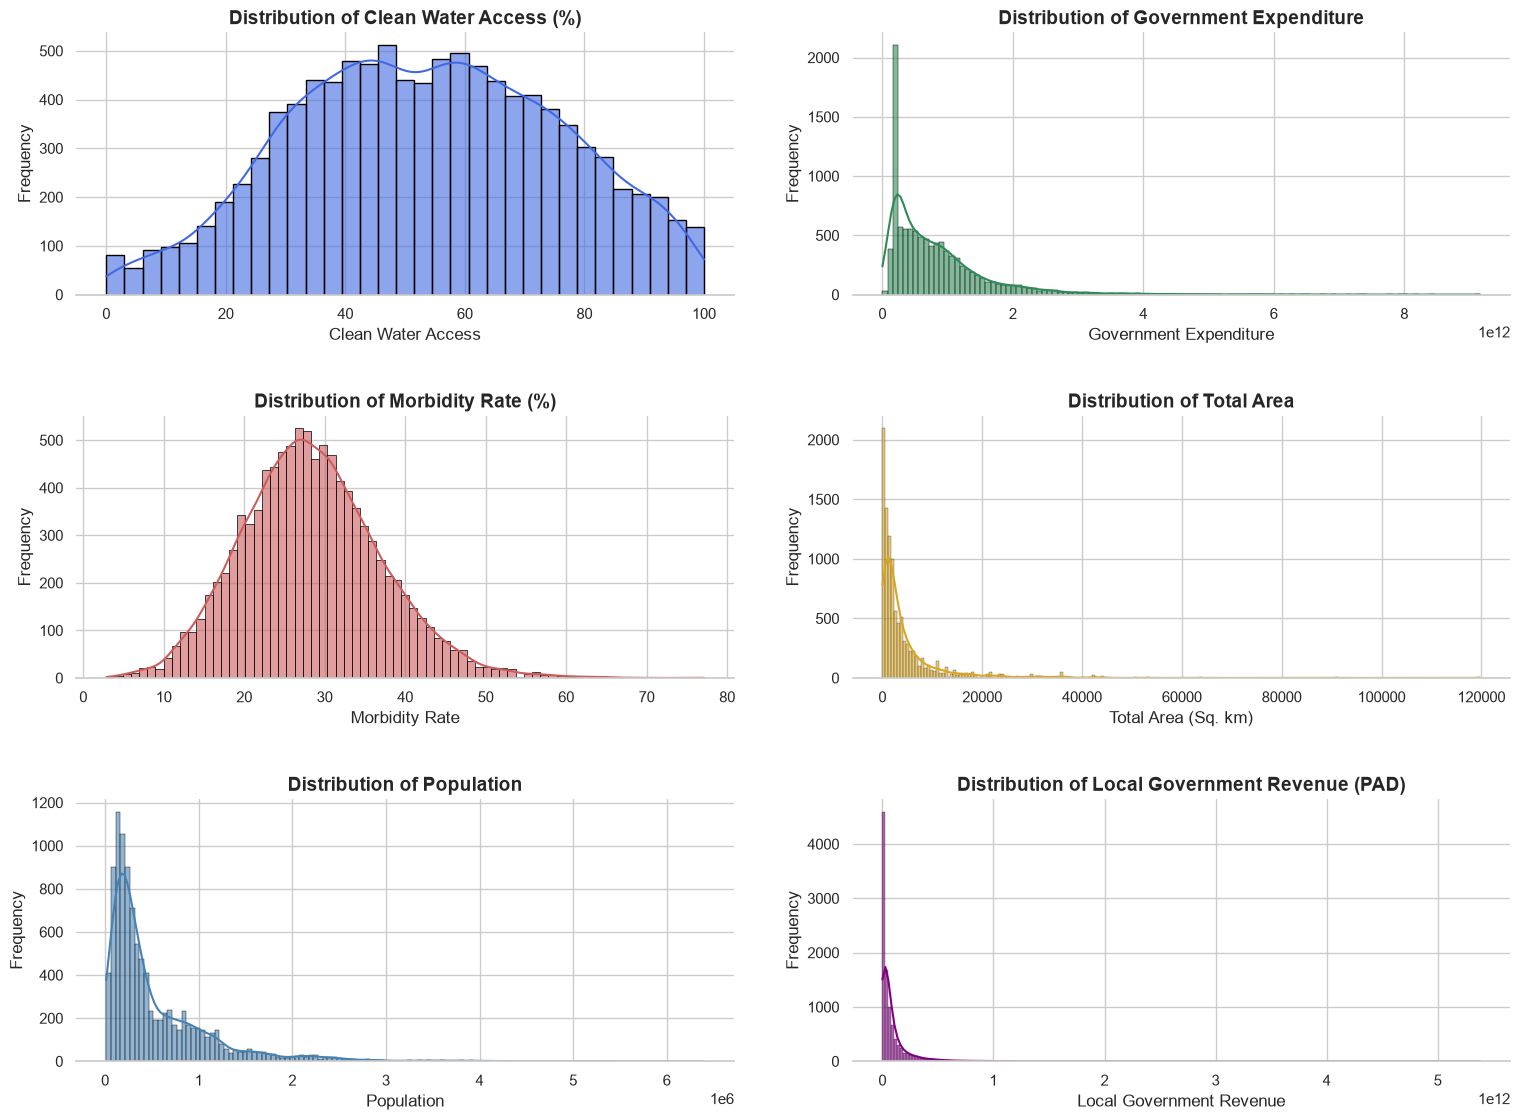

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean, academic visual theme
sns.set_theme(style="whitegrid", palette="muted")

# Initialize the figure with appropriate dimensions
fig = plt.figure(figsize=(16, 12))

# 1. Clean Water Access
plt.subplot(3, 2, 1) # Changed to 3x2 grid since you only have 6 graphs (looks better than 3x3)
sns.histplot(df['water'], kde=True, color="royalblue", edgecolor="black", alpha=0.6)
plt.title('Distribution of Clean Water Access (%)', fontsize=14, fontweight='bold')
plt.xlabel('Clean Water Access', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# 2. Government Expenditure
plt.subplot(3, 2, 2)
sns.histplot(df['expend'], kde=True, color="seagreen", edgecolor="black", alpha=0.6)
plt.title('Distribution of Government Expenditure', fontsize=14, fontweight='bold')
plt.xlabel('Government Expenditure', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# 3. Morbidity Rate
plt.subplot(3, 2, 3)
sns.histplot(df['morbid'], kde=True, color="indianred", edgecolor="black", alpha=0.6)
plt.title('Distribution of Morbidity Rate (%)', fontsize=14, fontweight='bold')
plt.xlabel('Morbidity Rate', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# 4. Total Area
plt.subplot(3, 2, 4)
sns.histplot(df['area'], kde=True, color="goldenrod", edgecolor="black", alpha=0.6)
plt.title('Distribution of Total Area', fontsize=14, fontweight='bold')
plt.xlabel('Total Area (Sq. km)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# 5. Population
plt.subplot(3, 2, 5)
sns.histplot(df['pop'], kde=True, color="steelblue", edgecolor="black", alpha=0.6)
plt.title('Distribution of Population', fontsize=14, fontweight='bold')
plt.xlabel('Population', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# 6. Local Government Revenue (PAD)
plt.subplot(3, 2, 6)
sns.histplot(df['pad'], kde=True, color="purple", edgecolor="black", alpha=0.6)
plt.title('Distribution of Local Government Revenue (PAD)', fontsize=14, fontweight='bold')
plt.xlabel('Local Government Revenue', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# Clean up layout and remove top/right borders for a minimalist look
sns.despine(left=True)
plt.tight_layout(pad=3.0)
plt.show()


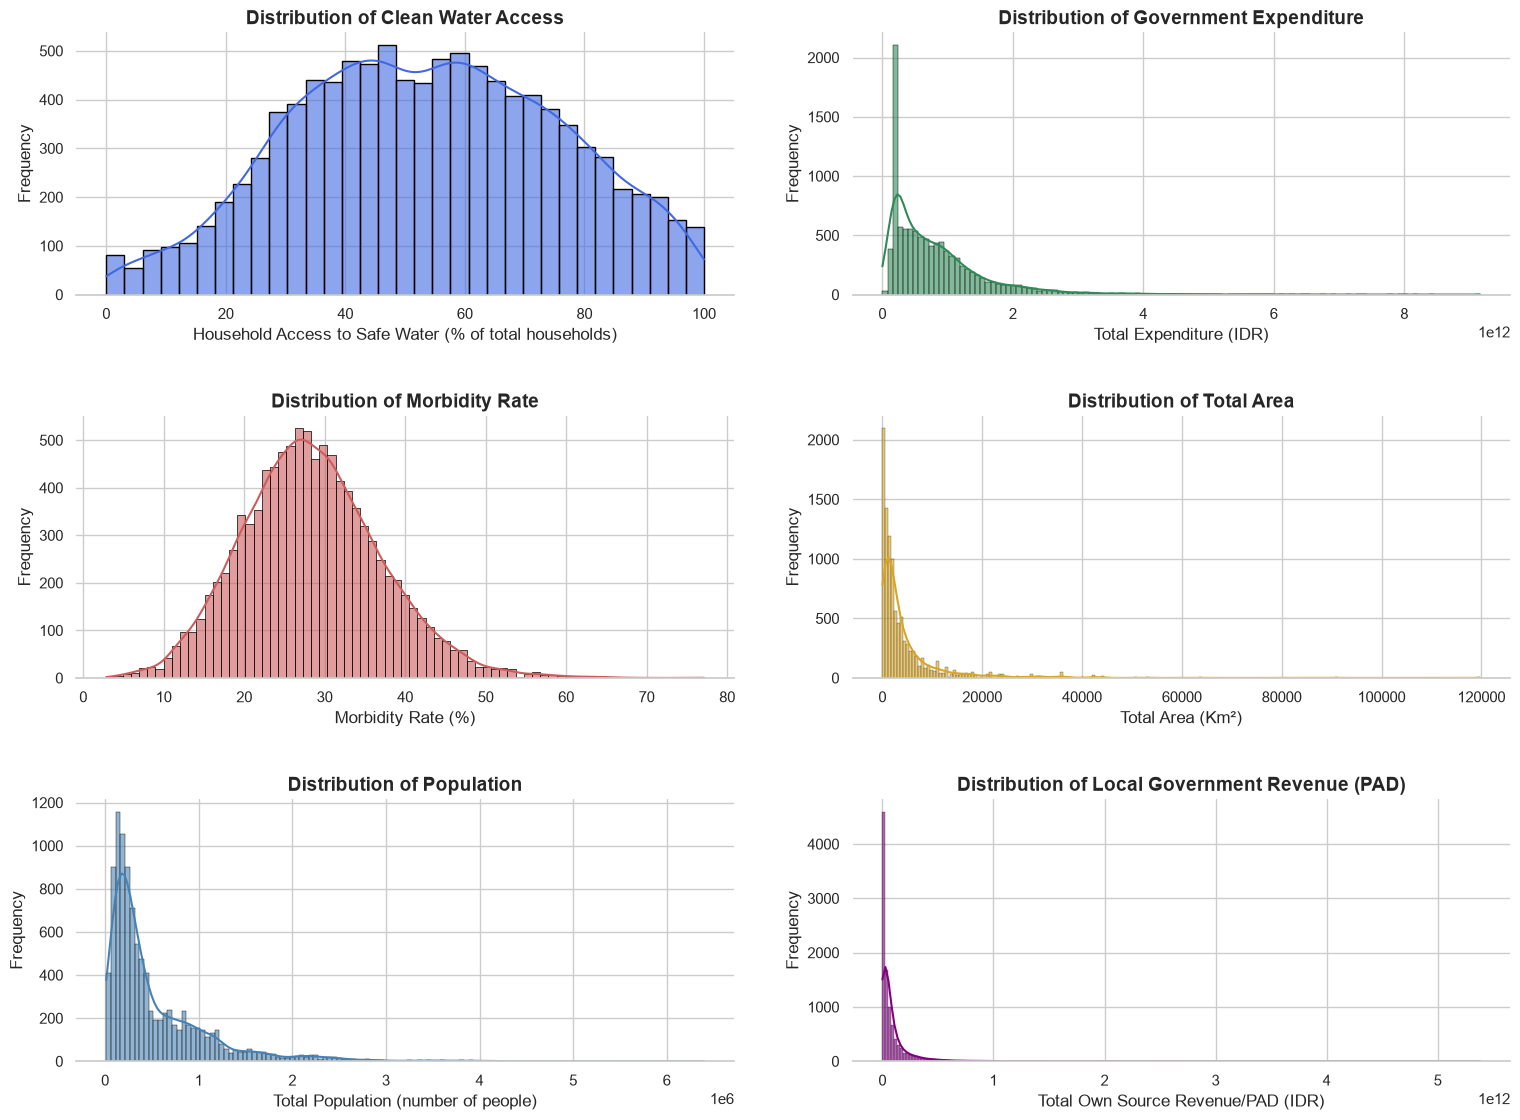

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
fig = plt.figure(figsize=(16, 12))

# 1. Clean Water Access
plt.subplot(3, 2, 1)
sns.histplot(df['water'], kde=True, color="royalblue", edgecolor="black", alpha=0.6)
plt.title('Distribution of Clean Water Access', fontsize=14, fontweight='bold')
plt.xlabel('Household Access to Safe Water (% of total households)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# 2. Government Expenditure
plt.subplot(3, 2, 2)
sns.histplot(df['expend'], kde=True, color="seagreen", edgecolor="black", alpha=0.6)
plt.title('Distribution of Government Expenditure', fontsize=14, fontweight='bold')
plt.xlabel('Total Expenditure (IDR)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# 3. Morbidity Rate
plt.subplot(3, 2, 3)
sns.histplot(df['morbid'], kde=True, color="indianred", edgecolor="black", alpha=0.6)
plt.title('Distribution of Morbidity Rate', fontsize=14, fontweight='bold')
plt.xlabel('Morbidity Rate (%)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# 4. Total Area
plt.subplot(3, 2, 4)
sns.histplot(df['area'], kde=True, color="goldenrod", edgecolor="black", alpha=0.6)
plt.title('Distribution of Total Area', fontsize=14, fontweight='bold')
plt.xlabel('Total Area (Km²)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# 5. Population
plt.subplot(3, 2, 5)
sns.histplot(df['pop'], kde=True, color="steelblue", edgecolor="black", alpha=0.6)
plt.title('Distribution of Population', fontsize=14, fontweight='bold')
plt.xlabel('Total Population (number of people)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# 6. Local Government Revenue (PAD)
plt.subplot(3, 2, 6)
sns.histplot(df['pad'], kde=True, color="purple", edgecolor="black", alpha=0.6)
plt.title('Distribution of Local Government Revenue (PAD)', fontsize=14, fontweight='bold')
plt.xlabel('Total Own Source Revenue/PAD (IDR)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

sns.despine(left=True)
plt.tight_layout(pad=3.0)
plt.show()


Figure Interpretation:

Figure 1 illustrates the empirical distributions of the primary variables utilized in this study. The distribution of Household Access to Safe Water exhibits a slight negative (left) skew, indicating that while a majority of regions maintain access levels between 40% and 80%, a distinct subset of regions continues to suffer from severe infrastructural deficits (near 0% access). Conversely, the Morbidity Rate follows a symmetric, roughly normal distribution centered tightly around 25% to 30%, suggesting a uniform baseline of public health challenges across the sample.

Notably, the structural and fiscal variables—Total Expenditure, Total Area, Total Population, and Total Own Source Revenue (PAD)—all demonstrate heavy-tailed, severe positive (right) skewness. This pronounced right-skewness is particularly extreme in the fiscal variables (Expenditure and PAD), reflecting profound regional inequality. The distributions indicate that while the vast majority of regions operate with limited fiscal capacity and small populations, a small number of outlier regions (likely major metropolitan centers) possess disproportionately massive populations and command the vast majority of local economic resources. These asymmetric distributions validate the necessity of employing robust empirical techniques to control for extreme regional disparities in the subsequent econometric analysis.

### Balance Check

In [31]:
df['daerah'].value_counts(ascending=True)

daerah
Mamberamo Tengah     8
Lanny Jaya          10
Puncak              10
Bengkulu Tengah     11
Sungai Penuh        11
                    ..
Mojokerto           50
Pasuruan            50
Probolinggo         50
Pontianak           50
Solok               50
Name: count, Length: 450, dtype: int64

In [32]:
df['year'].value_counts(ascending=True)

year
2000    275
1996    286
1997    287
1998    288
1999    289
2002    301
2001    321
2003    336
2004    371
2005    401
2006    432
2007    447
2008    447
2009    464
2015    473
2012    475
2019    475
2011    476
2013    476
2014    476
2016    476
2010    477
2017    477
2018    477
2020    477
Name: count, dtype: int64

In [33]:
df['tingkat'].value_counts(ascending=True)

tingkat
Kab       70
Kota    2000
Kab.    8110
Name: count, dtype: int64

In [34]:
df['tingkat'] = df['tingkat'].replace('Kab.', 'Kab')
df['tingkat'].value_counts(ascending=True)

tingkat
Kota    2000
Kab     8180
Name: count, dtype: int64

## Feature Engineering

create new feature

In [35]:
df['logpop'] = np.log(df['pop'])
df['logpad'] = np.log(df['pad'])
df['logarea'] = np.log(df['area'])
df['logexpend'] = np.log(df['expend'])

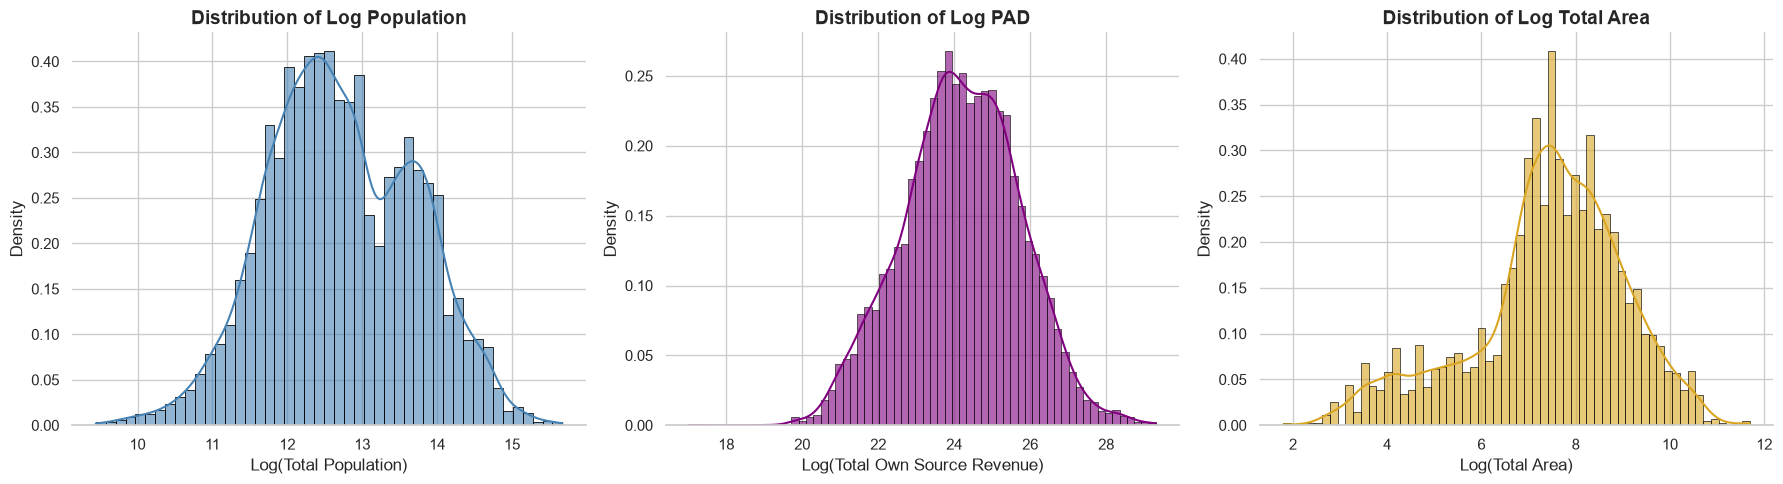

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set academic theme
sns.set_theme(style="whitegrid", palette="muted")

# Initialize figure (18x5 is perfect for a 1 row, 3 column layout)
fig = plt.figure(figsize=(18, 5))

# 1. Log of Population
plt.subplot(1, 3, 1)
sns.histplot(df['logpop'], kde=True, stat="density", color="steelblue", edgecolor="black", alpha=0.6)
plt.title('Distribution of Log Population', fontsize=14, fontweight='bold')
plt.xlabel('Log(Total Population)', fontsize=12)
plt.ylabel('Density', fontsize=12)

# 2. Log of Local Government Revenue (PAD)
plt.subplot(1, 3, 2)
sns.histplot(df['logpad'], kde=True, stat="density", color="purple", edgecolor="black", alpha=0.6)
plt.title('Distribution of Log PAD', fontsize=14, fontweight='bold')
plt.xlabel('Log(Total Own Source Revenue)', fontsize=12)
plt.ylabel('Density', fontsize=12)

# 3. Log of Total Area
plt.subplot(1, 3, 3)
sns.histplot(df['logarea'], kde=True, stat="density", color="goldenrod", edgecolor="black", alpha=0.6)
plt.title('Distribution of Log Total Area', fontsize=14, fontweight='bold')
plt.xlabel('Log(Total Area)', fontsize=12)
plt.ylabel('Density', fontsize=12)

# Clean borders and layout
sns.despine(left=True)
plt.tight_layout()
plt.show()


Figure Interpretation:

To address the severe positive skewness observed in the raw structural and fiscal data, a natural logarithmic transformation was applied to Population, Local Government Revenue (PAD), and Total Area. Figure 2 presents the distributions of these log-transformed variables. As anticipated, the log transformation successfully compresses the extreme right tails, stabilizing the variance and pulling the data closer to normality. Most notably, the distribution of Log PAD now closely approximates a Gaussian (normal) distribution, confirming that the transformation effectively resolves the extreme fiscal inequality outliers, making the variable highly suitable for standard linear econometric modeling.

Interestingly, the log transformations of Population and Total Area reveal distinct, underlying structural heterogeneity within the dataset. The Log Population distribution exhibits clear bimodality (two distinct peaks), suggesting that the sample is composed of two fundamentally different cohorts of regions—likely corresponding to densely populated urban municipalities (Kota) and smaller, less populated rural districts (Kabupaten). Similarly, the distribution of Log Area displays a prominent left-side shoulder, indicating a structural divide between geographically compact regions and massive, sprawling territories. These non-normal, multi-modal features in the geographic and demographic variables highlight the importance of controlling for regional status (e.g., urban vs. rural indicators) in subsequent regression analyses.

### Group the data

Peraturan yang mengatur pengklasifikasian kota berdasarkan jumlah penduduk di Indonesia adalah Peraturan Menteri Dalam Negeri (Permendagri) Nomor 137 Tahun 2017 tentang Klasifikasi dan Kodefikasi Wilayah Administrasi Pemerintahan. Permendagri ini menetapkan bahwa kota-kota di Indonesia dikelompokkan menjadi 4 kelas berdasarkan jumlah penduduknya, yaitu:

Kelas I: Kota dengan jumlah penduduk di atas 1 juta jiwa

Kelas II: Kota dengan jumlah penduduk antara 500 ribu hingga 1 juta jiwa

Kelas III: Kota dengan jumlah penduduk antara 100 ribu hingga 500 ribu jiwa

Kelas IV: Kota dengan jumlah penduduk di bawah 100 ribu jiwa


In [37]:
kondisi = [
    (df['pop'] <= 100000),
    (df['pop'] > 100000) & (df['pop'] <= 500000),
    (df['pop'] > 500000) & (df['pop'] <= 1000000),
    (df['pop'] > 1000000)
    ]

hasil = ['Kota Kecil', 'Kota Sedang', 'Kota Besar', 'Metropolitan']
df['status'] = np.select(kondisi, hasil, default='Lainnya')

df.head()

,id,year,water,expend,morbid,pop,pad,area,daerah,tingkat,daerah_lengkap,logpop,logpad,logarea,logexpend,status
20,ID.BA.BD,1996,42.52,1.977963e+11,28.46,315600.0,8.081535e+10,419.0,Badung,Kab,Kab. Badung,12.662231,25.115433,6.037871,26.010504,Kota Sedang
21,ID.BA.BD,1997,38.60,1.977963e+11,28.05,322100.0,9.578920e+10,419.0,Badung,Kab,Kab. Badung,12.682617,25.285416,6.037871,26.010504,Kota Sedang
22,ID.BA.BD,1998,40.72,1.977963e+11,23.42,328700.0,2.174454e+11,419.0,Badung,Kab,Kab. Badung,12.702901,26.105214,6.037871,26.010504,Kota Sedang
23,ID.BA.BD,1999,36.70,1.977963e+11,32.92,335300.0,2.539003e+11,419.0,Badung,Kab,Kab. Badung,12.722781,26.260208,6.037871,26.010504,Kota Sedang
24,ID.BA.BD,2000,48.57,1.977963e+11,26.37,339953.0,2.190000e+11,419.0,Badung,Kab,Kab. Badung,12.736563,26.112338,6.037871,26.010504,Kota Sedang


In [38]:
print(df.groupby('status')['id'].nunique())

status
Kota Besar      135
Kota Kecil       94
Kota Sedang     308
Metropolitan     83
Name: id, dtype: int64


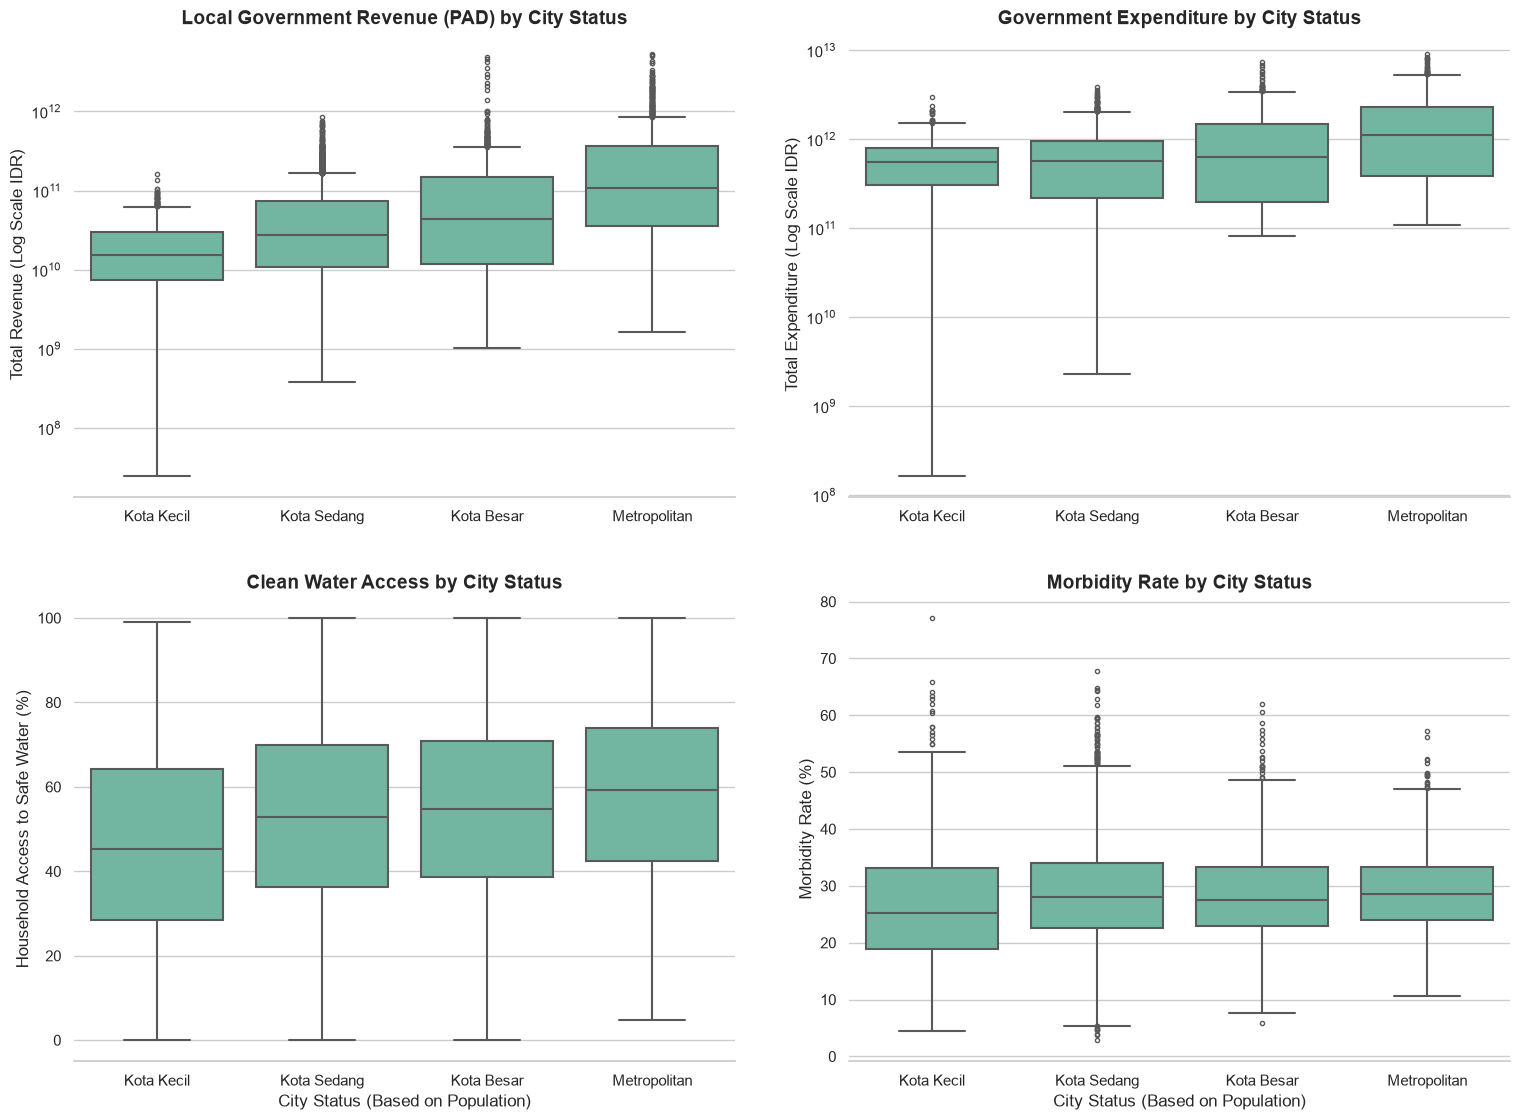

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set professional academic theme
sns.set_theme(style="whitegrid", palette="Set2")

# Create a 2x2 grid for the boxplots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Define the logical order of urbanization for the x-axis
city_order = ['Kota Kecil', 'Kota Sedang', 'Kota Besar', 'Metropolitan']

# 1. Boxplot: Local Government Revenue (PAD)
sns.boxplot(ax=axes[0, 0], data=df, x='status', y='pad', order=city_order, linewidth=1.5, fliersize=3)
axes[0, 0].set_yscale('log') # Log scale is CRITICAL here for readability
axes[0, 0].set_title('Local Government Revenue (PAD) by City Status', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('')
axes[0, 0].set_ylabel('Total Revenue (Log Scale IDR)', fontsize=12)

# 2. Boxplot: Government Expenditure
sns.boxplot(ax=axes[0, 1], data=df, x='status', y='expend', order=city_order, linewidth=1.5, fliersize=3)
axes[0, 1].set_yscale('log') # Log scale is CRITICAL here for readability
axes[0, 1].set_title('Government Expenditure by City Status', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('Total Expenditure (Log Scale IDR)', fontsize=12)

# 3. Boxplot: Clean Water Access
sns.boxplot(ax=axes[1, 0], data=df, x='status', y='water', order=city_order, linewidth=1.5, fliersize=3)
axes[1, 0].set_title('Clean Water Access by City Status', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('City Status (Based on Population)', fontsize=12)
axes[1, 0].set_ylabel('Household Access to Safe Water (%)', fontsize=12)

# 4. Boxplot: Morbidity Rate
sns.boxplot(ax=axes[1, 1], data=df, x='status', y='morbid', order=city_order, linewidth=1.5, fliersize=3)
axes[1, 1].set_title('Morbidity Rate by City Status', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('City Status (Based on Population)', fontsize=12)
axes[1, 1].set_ylabel('Morbidity Rate (%)', fontsize=12)

# Adjust layout
sns.despine(left=True)
plt.tight_layout(pad=3.0)
plt.show()


Figure Interpretation:

Figure 3 presents a comparative boxplot analysis of fiscal capacities, infrastructural access, and health outcomes stratified by regional population thresholds (from Kota Kecil to Metropolitan).

As expected through the lens of agglomeration economics, there is a distinct, monotonically increasing relationship between city scale and fiscal capacity. Both Local Government Revenue (PAD) and Government Expenditure exhibit significantly higher medians and upper quartiles as regions transition from small municipalities to metropolitan areas. The presence of upper-bound outliers within the Metropolitan category further underscores the extreme concentration of capital in top-tier urban centers.

Regarding infrastructural and health outcomes, the distribution of Clean Water Access demonstrates that larger urban centers generally achieve higher median coverage compared to Kota Kecil and Kota Sedang. However, the persistent variance and lower whiskers across all city tiers indicate that infrastructural deficits are not exclusively a rural or small-city phenomenon, but rather a persistent systemic issue. Conversely, the Morbidity Rate distributions provide insight into the potential presence of an "urban penalty." While metropolitan areas possess superior fiscal resources to combat health crises, their elevated population densities may paradoxically tighten the variance or shift the median morbidity rates when compared to smaller, less congested regions. Ultimately, the boxplots confirm that population scale acts as a critical structural determinant for both regional economic capacity and infrastructural provisioning.

### Correlation Heatmap

<Axes: >

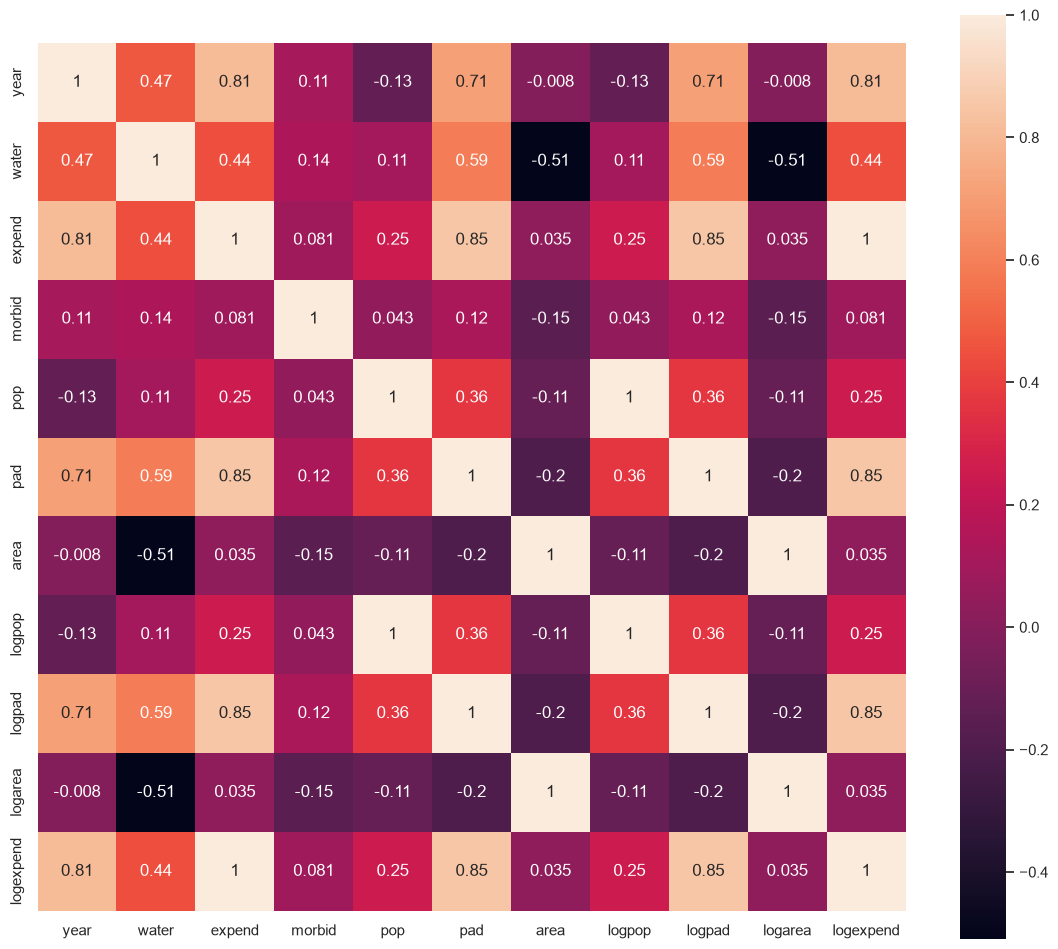

In [40]:
plt.figure(figsize=(14,12))
# Add numeric_only=True here!
corr = df.corr(method='spearman', numeric_only=True)
sns.heatmap(corr, annot=True, square=True)


Figure [X] presents the Spearman rank-order correlation matrix for the primary structural, fiscal, and health indicators. The use of Spearman’s rank correlation is methodologically appropriate here, as it is robust against the severe non-normality and extreme outliers observed in the raw fiscal and geographic variables. (Note: Because Spearman evaluates monotonic relationships via rank, the correlations for the log-transformed variables—logpop, logpad, logarea, logexpend—are mathematically identical to their raw counterparts, confirming the stability of the ranking structure).

Several critical insights emerge from the matrix that validate the theoretical framework of this study:

1. The Fiscal Determinants of Infrastructure Access to clean water (water) exhibits a strong positive correlation with Local Government Revenue (pad, ρ = 0.59) and Government Expenditure (expend, ρ = 0.44). This robust relationship confirms that regional fiscal capacity is a primary driver of infrastructural development; wealthier, highly-resourced local governments are significantly more capable of financing and maintaining widespread clean water access for their populations.

2. The Geographic Penalty on Water Access Conversely, there is a strong negative correlation between clean water access and regional area (area, ρ = -0.51). This indicates a significant "geographic penalty"—vast, sprawling regions face substantially higher logistical and financial barriers to establishing centralized piped-water infrastructure compared to compact, densely populated urban municipalities.

3. Temporal Improvements in Infrastructure The moderate positive correlation between year and water (ρ = 0.47) provides empirical evidence that, in aggregate, clean water access has steadily improved across the 25-year panel period, reflecting the cumulative impact of national development policies. Furthermore, year is highly correlated with both expend (ρ = 0.81) and pad (ρ = 0.71), capturing the macroeconomic inflation and general economic expansion of local governments over the last two decades.

4. The Complexity of the Morbidity Rate Interestingly, the morbidity rate (morbid) exhibits very weak, almost negligible correlations across all structural and fiscal variables (all ρ < 0.15). The slightly positive correlation between morbid and variables like water (ρ = 0.14) and pad (ρ = 0.12) is counterintuitive but commonly observed in empirical development economics; wealthier, more developed regions often report higher morbidity rates simply because they possess superior healthcare diagnostics, better public health reporting infrastructure, and higher population densities (the "urban penalty"), which leads to higher recorded incidences of illness compared to rural, under-resourced regions where illnesses go undiagnosed.

### Temporal Analytics

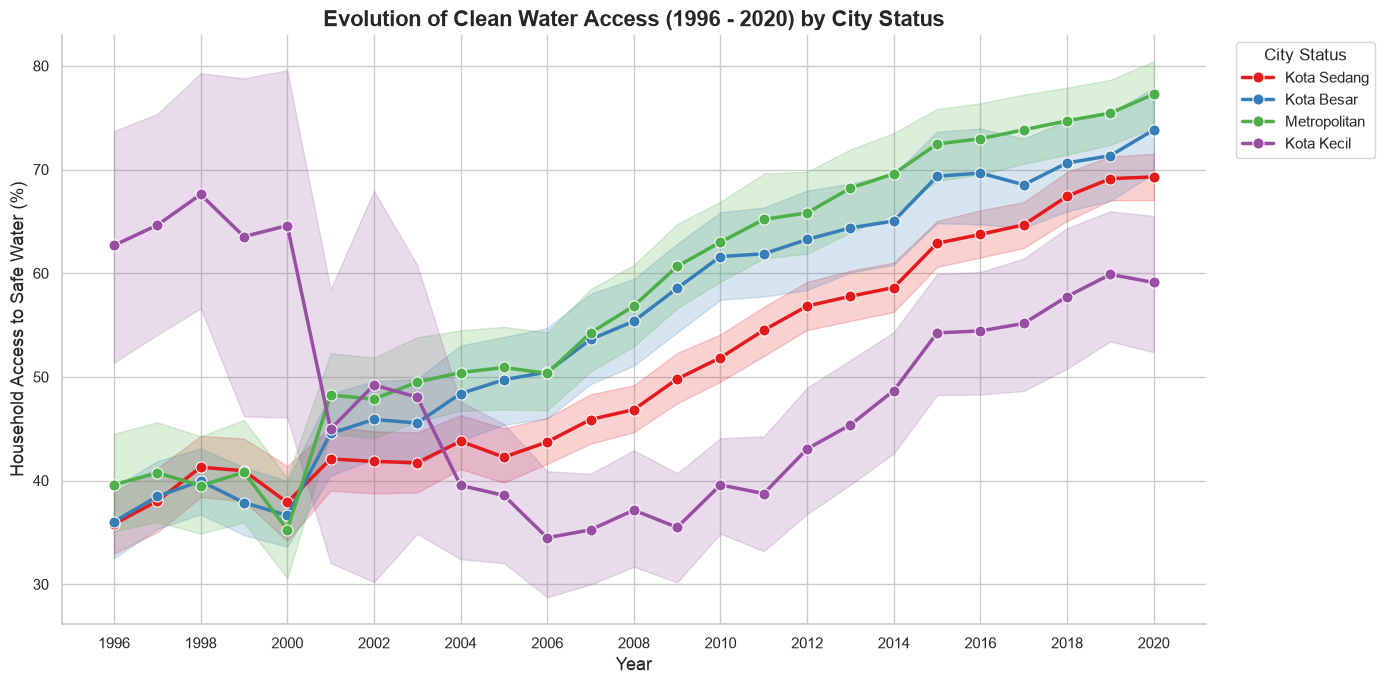

In [41]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 7))
sns.set_theme(style="whitegrid", palette="Set1")

sns.lineplot(data=df, x='year', y='water', hue='status', 
             marker="o", linewidth=2.5, markersize=8)

plt.title('Evolution of Clean Water Access (1996 - 2020) by City Status', fontsize=16, fontweight='bold')
plt.xlabel('Year', fontsize=13)
plt.ylabel('Household Access to Safe Water (%)', fontsize=13)

plt.legend(title='City Status', title_fontsize='12', fontsize='11', 
           bbox_to_anchor=(1.02, 1), loc='upper left')

plt.xticks(np.arange(df['year'].min(), df['year'].max() + 1, 2))

sns.despine()
plt.tight_layout()
plt.show()


In [42]:
# Group the data by year and status, then count the number of rows (regions)
status_counts_per_year = df.groupby(['year', 'status']).size().unstack(fill_value=0)

# Display the table (I added .tail(20) just in case it's too long, but you can remove it to see all years)
status_counts_per_year


status,Kota Besar,Kota Kecil,Kota Sedang,Metropolitan
year,,,,
1996,90,9,136,51
1997,90,9,137,51
1998,89,8,137,54
1999,96,8,131,54
2000,82,7,130,56
2001,81,17,166,57
2002,78,11,153,59
2003,75,14,186,61
2004,66,28,215,62


In [43]:
import plotly.graph_objects as go
import pandas as pd

# Use the new 'daerah_lengkap' column as the index!
df_sankey = df[df['year'].isin([1996, 2008, 2020])].pivot(
    index='daerah_lengkap', 
    columns='year', 
    values='status'
).dropna()

# 2. Append the year to the status so the nodes in the diagram are distinct
df_sankey['1996'] = df_sankey[1996] + " '96"
df_sankey['2008'] = df_sankey[2008] + " '08"
df_sankey['2020'] = df_sankey[2020] + " '20"

# 3. Create a unique list of all nodes
all_nodes = list(pd.unique(df_sankey[['1996', '2008', '2020']].values.ravel('K')))
node_dict = {node: i for i, node in enumerate(all_nodes)}

# 4. Calculate the flows (how many regions moved from Status A to Status B)
flow1 = df_sankey.groupby(['1996', '2008']).size().reset_index(name='count')
flow1.columns = ['source', 'target', 'value']

flow2 = df_sankey.groupby(['2008', '2020']).size().reset_index(name='count')
flow2.columns = ['source', 'target', 'value']

links = pd.concat([flow1, flow2], axis=0)

links['source_id'] = links['source'].map(node_dict)
links['target_id'] = links['target'].map(node_dict)

# 5. Build the Sankey Diagram
fig = go.Figure(data=[go.Sankey(
    node = dict(
      pad = 20,
      thickness = 30,
      line = dict(color = "black", width = 0.5),
      label = all_nodes,
      color = "royalblue"
    ),
    link = dict(
      source = links['source_id'], 
      target = links['target_id'],
      value = links['value'],
      color = "rgba(169, 169, 169, 0.4)" 
  ))])

fig.update_layout(title_text="Migration of City Status Based on Population Growth (1996 - 2008 - 2020)", 
                  font_size=12, height=600)
fig.show(renderer="browser")



Explaining the Volatility in 'Kota Kecil' (Small Municipalities)
The highly eccentric and volatile trajectory of clean water access in the Kota Kecil cohort—characterized by massive variance between 1996–2000, a structural depression in 2008, and subsequent recovery—can be scientifically explained through four intersecting demographic and institutional mechanisms:

1. The Shock of Decentralization and Pemekaran Daerah
The erratic data immediately following 1998 is a direct artifact of Indonesia's radical shift toward "Big Bang" decentralization (Law No. 22/1999). This policy triggered a massive wave of Pemekaran Daerah (regional proliferation/splitting). Hundreds of new, autonomous small districts and municipalities (Kota/Kabupaten Kecil) were abruptly formed. These newly birthed regions were often carved out of the rural, under-developed peripheries of larger parent districts. Consequently, they entered the Kota Kecil dataset with severe infrastructural deficits, artificially dragging down the cohort's aggregate average. Furthermore, these nascent local governments initially lacked the institutional and fiscal capacity (PAD) to immediately build capital-intensive water networks, prolonging their infrastructural lag.

2. Compositional Attrition (The "Graduation" Effect)
The noticeable depression in the Kota Kecil trendline around 2008 is largely attributable to compositional bias within the panel data. Urbanization and economic agglomeration dictate that the most successful, fiscally capable small cities will experience rapid population growth. As these thriving regions crossed the 100,000 population threshold, they "graduated" into the Kota Sedang (Medium City) cohort, taking their high water-access metrics with them. The regions left behind in the Kota Kecil category were disproportionately those suffering from economic stagnation, geographic isolation, or out-migration. Thus, the apparent drop in average water access was not necessarily a destruction of existing infrastructure, but a statistical reflection of the strongest municipalities exiting the sample.

3. Macroeconomic Shocks and Asymmetric Recovery
The extreme variance and drop observed between 1996 and 2000 coincides with the 1997-1998 Asian Financial Crisis. During this period of severe fiscal contraction, national infrastructure spending was drastically curtailed. Theoretical models of crisis economics suggest an asymmetric recovery: limited government funds are typically triaged to stabilize core Metropolitan and Kota Besar centers to prevent total economic collapse. Kota Kecil regions, lacking political leverage and robust local revenue (PAD), were disproportionately abandoned during the recovery phase, resulting in the widening infrastructural gap seen in the early 2000s.

4. The Post-2011 Catch-Up Phase
The sharp, sustained upward trajectory of Kota Kecil from 2011 onwards represents the stabilization of decentralization. By this decade, the central government had aggressively expanded the Dana Alokasi Khusus (DAK - Special Allocation Funds) specifically targeted at basic infrastructure in lagging regions. The data proves that once institutional capacity stabilized and targeted fiscal transfers matured, the Kota Kecil cohort finally entered a rapid "catch-up" phase, converging toward the national baseline.

In [45]:
df.to_csv('/Users/yudhapratama/Documents/Science/Publikasi/clean-water-access/data/clean_water.csv',index=False)